# NFL Game Simulator v2

**Keep `nfl_game_sim.py` in the same folder as this notebook.** First run downloads ~90 MB of nflverse data (play-by-play 2023-2026, rosters, depth charts, injury reports) into `nfl_data/`. Later runs read the cache. Delete a file in `nfl_data/` to force a refresh; do that each week for new rosters and injury reports.

**How a game is simulated.** Coin toss, then possession by possession on a real 60-minute clock. Each drive starts at an actual field position and ends in a TD, FG, missed FG, punt, turnover, or turnover on downs, with odds and time used drawn from real NFL drives and tilted for the two teams. The next drive starts where the ball ended up: a pick at midfield hands over a short field, pick-sixes score, scores lead to kickoffs. Possession counts and turnovers vary game to game. Tied games go to 2025-rules overtime.

**What tilts the odds**
| Factor | Source |
|---|---|
| Team efficiency | Opponent-adjusted EPA/play (pass and run split) blended with points ratings |
| Starting QB | Depth chart QB1 (skips injured/reserve), rated by EPA per dropback |
| QB mistakes | QB interceptions + lost fumbles per dropback, drives the turnover odds |
| Skill players | WR/TE/RB value above replacement; removed if on IR/PUP/NFI or injury report, moved with the player on trades/signings |
| Game plan vs similar teams | Pass rate the offense used vs defenses built like this opponent (and this exact opponent) |
| Style matchup | How the offense over/under-performed vs similar defenses |
| 4th-down aggressiveness | Head coach go-for-it rate over expected, punt zone and FG zone |
| Halftime adjustments | Coach 2nd-half vs 1st-half efficiency swing, offense and defense |
| Head-to-head | Meetings in the last 2 years vs what ratings expected (heavily shrunk) |

In [28]:
# First time only
# %pip install pandas numpy pyarrow matplotlib

In [29]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from nfl_game_sim import *

games, pbp, injuries = load_all([2023, 2024, 2025, 2026])
prep = prepare(games, pbp)
print(f"{len(pbp):,} plays loaded | latest 2026 week with data: {int(pbp[pbp.season == 2026].week.max())}")

156,084 plays loaded | latest 2026 week with data: 3


## 1. Current rosters, injuries, and ratings
Ratings use every game played before `AS_OF`. Rosters and depth charts are the latest nflverse snapshot. Until the Week 4 injury report comes out (Wed-Fri), the Week 3 report carries forward at reduced weight (Out 70%, Doubtful 50%, Questionable 15%). Anyone on IR, PUP, NFI, or suspended counts as out.

In [32]:
SEASON, WEEK, AS_OF = 2026, 4, "2026-09-29"

rosters, depth = load_rosters(SEASON)
ctx = build_context(SEASON, WEEK, rosters, injuries, depth, carry_forward=True)
model = fit_model(prep, AS_OF)

rw = rosters[rosters.week == rosters.week.max()]
res = rw[rw.status == "RES"].status_description_abbr.map(RESERVE_LABELS).fillna("other reserve")
print("Players on reserve lists:", res.value_counts().to_dict())
print("Players with any availability hit this week:", len(ctx["miss"]))

Players on reserve lists: {'IR': 187, 'IR (designated to return)': 50, 'PUP': 30, 'NFI': 10, 'suspended': 1, 'other reserve': 1}
Players with any availability hit this week: 502


## 2. Simulate one game
Optional overrides: `HOME_QB` / `AWAY_QB` to force a starter by name (e.g. `"J.Allen"`), `OUT` to rule out players by name (format like `"C.McCaffrey"`).

PHI (J.Hurts) @ CHI (T.Taylor)
  Win prob:    CHI 55.3% | PHI 44.1% | tie 0.6%
  Final proj:  CHI 23.7 - PHI 22.0   (halftime 10.3 - 11.6)
  Line:        CHI -1.8   Total 45.7
  Possessions: CHI 10.9, PHI 10.9   Turnovers: CHI 1.31, PHI 1.29
  Most likely finals: CHI 27 - PHI 20 (0.9%), CHI 20 - PHI 17 (0.8%), CHI 20 - PHI 27 (0.8%)


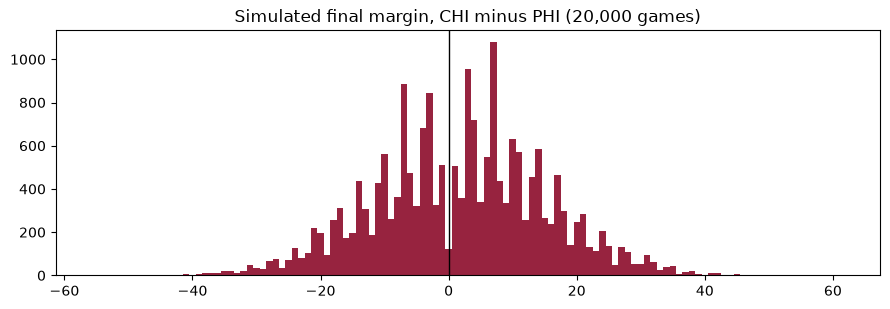

In [33]:
HOME, AWAY, NEUTRAL = "CHI", "PHI", False
HOME_QB, AWAY_QB, OUT = "T.Taylor", None, ["T.Bagent"]

result = simulate_game(model, HOME, AWAY, n_sims=20000, neutral=NEUTRAL, seed=42,
                       home_qb=HOME_QB, away_qb=AWAY_QB, out_players=OUT, ctx=ctx)
print_game(result)

margin = result["home_scores"] - result["away_scores"]
plt.figure(figsize=(9, 3.2))
plt.hist(margin, bins=np.arange(margin.min() - .5, margin.max() + 1.5), color="#97233F")
plt.axvline(0, color="black", lw=1)
plt.title(f"Simulated final margin, {HOME} minus {AWAY} (20,000 games)")
plt.tight_layout(); plt.show()

### What moved the line
Factors added one at a time, so you can see what each stat is worth in this matchup.

In [21]:
factor_breakdown(model, HOME, AWAY, ctx=ctx, home_qb=HOME_QB, away_qb=AWAY_QB, out_players=OUT)

,factor added,CHI margin,change,CHI win %
0,Team points ratings only,4.1,0.0,61.4
1,EPA efficiency (pass/run),2.6,-1.5,57.4
2,Starting QB,-0.5,-3.1,47.9
3,Skill players out,-0.0,0.4,49.5
4,Game plan vs similar D,-0.2,-0.2,49.0
5,Style matchup residual,1.3,1.5,52.9
6,Turnover tendencies / QB mistakes,1.4,0.1,54.1
7,4th-down aggressiveness,1.4,-0.0,53.7
8,Halftime adjustments,1.3,-0.0,53.8
9,Head-to-head (2 yrs),1.7,0.4,55.6


## 3. Full week vs. Vegas
Negative line = home team favored. Big gaps usually mean the model is missing something, not that you found an edge.

In [22]:
simulate_week(model, SEASON, WEEK, ctx=ctx)

,matchup,QBs,home_win_%,model_line,vegas_line,model_total,vegas_total
0,PIT @ CLE,A.Rodgers / D.Watson,54.9,-1.7,2.5,40.3,38.5
1,IND @ WAS,D.Jones / M.Mariota,51.4,-0.5,3.0,52.5,47.5
2,TEN @ BAL,C.Ward / L.Jackson,76.2,-9.6,-11.5,47.3,43.5
3,NE @ BUF,D.Maye / J.Allen,56.8,-2.3,-7.0,49.1,48.5
4,NYJ @ CHI,G.Smith / T.Bagent,68.9,-6.6,-3.0,46.7,42.5
5,JAX @ CIN,T.Lawrence / J.Burrow,35.0,5.2,-2.5,50.1,51.5
6,DAL @ HOU,D.Prescott / C.Stroud,54.2,-1.6,-2.5,49.4,47.5
7,ARI @ NYG,J.Brissett / J.Winston,53.5,-1.3,1.5,45.0,44.5
8,LA @ PHI,M.Stafford / J.Hurts,46.3,1.1,1.5,46.2,46.5
9,GB @ TB,J.Love / B.Mayfield,53.3,-1.0,3.5,47.5,39.5


## 4. Coach and QB tendencies
`4th_GOE` = go-for-it rate above what an average coach does in the same spot (+0.10 = goes 10 points more often). Halftime swings are in EPA/play and heavily shrunk; most coaches sit near zero because the effect barely repeats year to year.

In [23]:
coach_table(model)

,coach,4th_GOE_punt_zone,4th_GOE_fg_zone,halftime_off_swing,halftime_def_swing
team,,,,,
DAL,Brian Schottenheimer,0.128,0.041,-0.031,0.023
IND,Shane Steichen,0.093,0.015,-0.015,-0.026
CAR,Dave Canales,0.070,-0.006,0.028,0.027
BUF,Sean McDermott,0.064,0.153,0.020,0.049
DET,Dan Campbell,0.059,0.168,0.010,-0.037
ATL,Raheem Morris,0.042,0.008,-0.010,-0.021
KC,Andy Reid,0.042,-0.075,0.005,0.004
NYG,John Harbaugh,0.041,0.005,0.052,-0.038
PHI,Nick Sirianni,0.039,0.068,-0.053,-0.017


In [24]:
qb_table(model).head(32)

,name,team,db,epa_per_db,turnover_pct
qb_id,,,,,
00-0037834,B.Purdy,SF,473,0.184,2.564
00-0033077,D.Prescott,DAL,775,0.130,1.969
00-0034857,J.Allen,BUF,741,0.112,2.857
00-0033106,J.Goff,DET,740,0.110,1.875
00-0039918,C.Williams,CHI,805,0.092,2.434
00-0026498,M.Stafford,LA,865,0.091,2.545
00-0034796,L.Jackson,BAL,456,0.086,2.612
00-0036971,T.Lawrence,JAX,762,0.085,2.532
00-0033873,P.Mahomes,KC,698,0.082,2.429


## 5. Does it hold up? (backtest, ~2 min per season)
Every week of 2024 and 2025 from Week 4 on: refit using only earlier games, use that week's roster and injury report and the actual starting QBs, then grade against the result and the Vegas closing line. `none` = the same game engine with just team points ratings.

In [9]:
rw_hist = pd.concat([load_rosters(y)[0] for y in (2024, 2025)])
rows = {}
for yr in (2024, 2025):
    for name, feats in (("all factors", ALL_FEATURES), ("none", ())):
        _, s = backtest(games, prep, injuries, rw_hist, yr, n_sims=2500, features=feats)
        rows[f"{yr} {name}"] = s
pd.DataFrame(rows).T[["games", "pick_acc", "vegas_pick_acc", "brier", "margin_MAE", "vegas_margin_MAE", "total_MAE"]].round(3)

,games,pick_acc,vegas_pick_acc,brier,margin_MAE,vegas_margin_MAE,total_MAE
2024 all factors,224.0,0.732,0.741,0.204,9.926,9.277,9.910
2024 none,224.0,0.701,0.741,0.208,10.208,9.277,10.119
2025 all factors,224.0,0.619,0.632,0.226,10.416,9.924,10.259
2025 none,224.0,0.619,0.632,0.227,10.476,9.924,10.364
